# Qiskit-Metal-to-Litho six-Xmon chip: a Quantcore-PDK rebuild, step by step

**Source:** Onri Jay Benally (OJB-Quantum), **Qiskit-Metal-to-Litho**,
`6_Xmon_Layout_with_Quantum_Metal_PHIDL_GDSTK_in_Colab.ipynb`, <https://github.com/OJB-Quantum/Qiskit-Metal-to-Litho>,
licence **CC BY 4.0** (`LICENSE`; attribution: © Onri Jay Benally, adapted). The notebook's design constants were
read on 2026-11-03 (never executed). Spec: `docs/designs/community/qm2litho_6xmon.md`.

**What the chip is:** six Metal `TransmonCross` qubits in two columns of three, one column on each side of a straight
vertical feedline (11.7/5.1 µm) between two `LaunchpadWirebond`s. Each qubit has a claw toward the line and a λ/4
meander readout coupled through a `CoupledLineTee` (200 µm coupled, 4 µm ground strip, shorted, 110 µm down leg).
Readout targets 6.116–6.704 GHz come from L = v / (4 f) with v = 1.2 × 10⁸ m/s. The cross and L_J (15.904 nH) are those
of the SQuADDS tutorial-5 qubit. A second section of the source notebook writes a **cheesed variant** of the same
chip: an antidot (vortex-trap) field of 2 µm squares on a 10 µm pitch, 15 µm from the metal (45 µm round the pads).

**This notebook rebuilds the chip in the Quantcore PDK; it is not a replica.** What the rebuild keeps and what the PDK
changes:

| topic | source (Qiskit-Metal-to-Litho) | this rebuild |
|---|---|---|
| die and frame | Metal's 5 × 5 mm chip centred on (0, 0), no frame; the pads overhang it by 83 µm | PDK 5 × 5 mm die (Designer = source + (2500, 2500) µm): dicing L's, alignment grids, device ID `QM2L-6X` |
| stack | silicon (Metal default) | PDK sapphire 650 µm, εr 10.25 |
| qubits, launchpads | Metal `TransmonCross`, `LaunchpadWirebond` | the same cells and options through the `metal:` wrappers |
| junction | lumped L_J 15.904 nH (`hfss_inductance`) | Quantcore Nb trilayer junction drawn for L_J = 15.904 nH (`trilayer_junction`); R_n is flagged, not retuned |
| readout coupler | `CoupledLineTee` + `RouteMeander` | one qcc λ/4 hanger route per qubit: claw → meander → 200 µm coupled section (4 µm strip) → short |
| launchpads | at y ±2100 µm, overhanging the chip | **PDK pad rule**: outer etch `frame.pad_edge` = 100 µm inside the north / south die edges |
| cheese | the cheesed variant: 2 µm antidots, 10 µm pitch, 15 µm clearance | **the original's cheese**: the same antidot field as the chip's `cheese` rule, drawn by the build and kept in the mask; no PDK band |
| netlist, LOM, FEM jobs | none | our netlist, LOM and Q3D / eigenmode job exports per qubit |

## 1 · Setup and the PDK

The notebook runs from the repository root. `_common` holds the table, snapshot and PDK helpers shared by the design
notebooks. `LIVE` follows `QCC_LIVE`: with KLayout open, every change below shows up live; with `QCC_LIVE=0` (tests,
batch runs) the snapshots are rendered headless.

In [1]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.circuit.bridges import rn_from_lj

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/community")
OUT.mkdir(parents=True, exist_ok=True)

The PDK facts this chip relies on. Every rule is applied by the library, not by this notebook: the frame and the cheese by
the chip build, the pad rule by `edge=`, the junction by `trilayer_junction`, the design warnings by the DRC.

In [2]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 2 · The die and the frame

`Designer(name, box=...)` opens an empty chip. The box is the source's 5 × 5 mm chip, so Designer = source +
(2500, 2500) µm. The PDK draws the frame round it: L dicing markers (1000/0), 3 × 3 alignment grids (1001/0), the chip
boundary (100/0) and the device ID (`name_chip`) on a free edge.

**Cheese: the original's.** The source's cheesed variant has an antidot (vortex-trap) field: 2 µm squares on a 10 µm
pitch, 15 µm from the metal. The original wins, so the chip carries that field as its `cheese` rule (`size`, `gap`,
`rows`, `clearance`) and the build draws it instead of the PDK band (layout, snapshots, KLive and the mask). The rule's
`clearance` is measured from the 3/0 keep-out, which already adds the PDK route margin (10 µm) round each CPW, so
15 − 10 = 5 µm keeps the holes 15 µm from the line etch, as in the source (and further from the components, whose
keep-out margin is larger). `rows` 1000 fills the whole free ground. The source's wider 45 µm round the pads is not
reproduced (one clearance for everything).

chip cheese rule: {'size': 2.0, 'gap': 8.0, 'rows': 1000, 'clearance': 5.0}


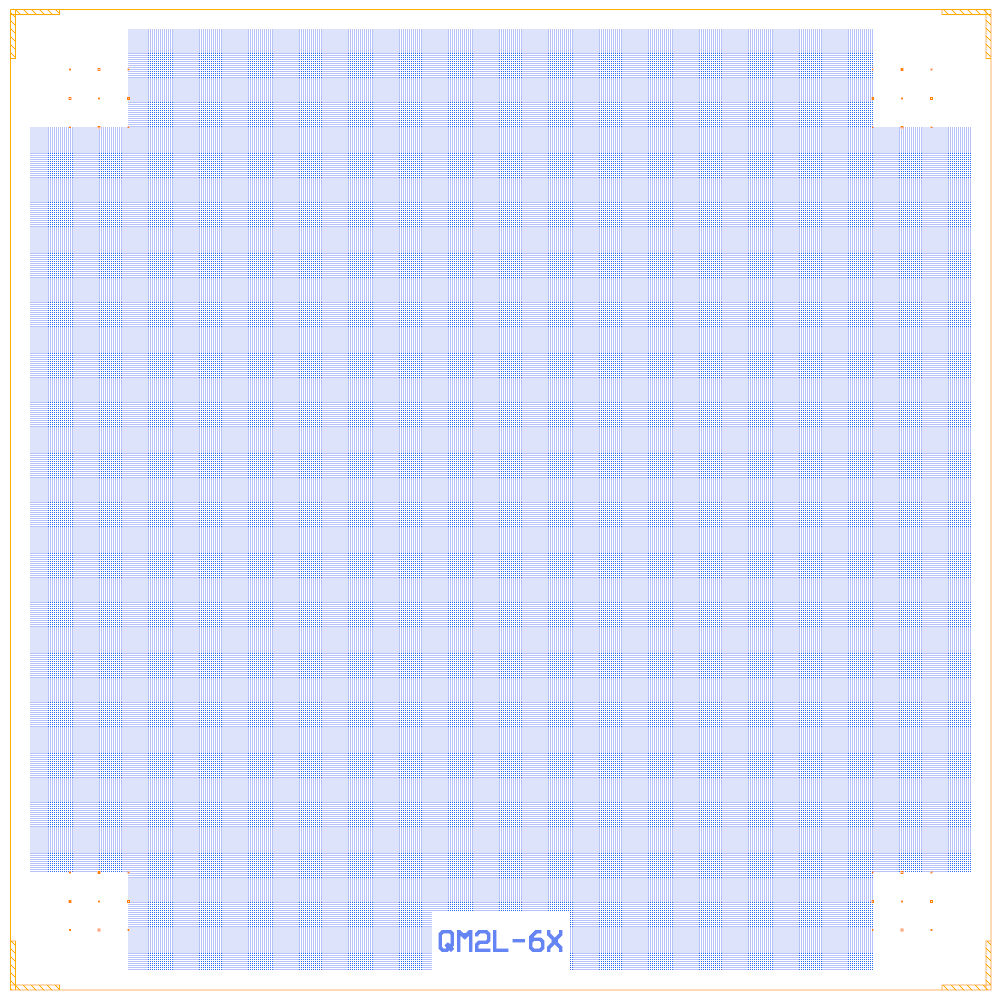

In [3]:
from quantcore_circuits.pdk import get_pdk

X0, Y0 = 2500, 2500                              # Metal's 5 × 5 mm chip is centred on (0, 0)
ANTIDOTS = {"size": 2.0, "gap": 8.0, "rows": 1000,  # the source's field: 2 µm squares on a 10 µm pitch,
            "clearance": 15.0 - get_pdk().keepout.route_margin}   # 15 µm from the CPW etch (3/0 adds 10 µm)
d = Designer("qm2litho_6xmon", box=(0, 0, 5000, 5000),
             chip={"name_chip": "QM2L-6X", "cheese": ANTIDOTS}, live=LIVE)
print("chip cheese rule:", d.design.chip.params["cheese"])
snap(d, OUT / "qm2litho_6xmon_die.png", size=(1000, 1000), width=360);

## 3 · Pads: the two launchpads and the PDK pad rule

The source puts its two `LaunchpadWirebond`s (160 × 200 µm pad, 58 µm gap, 200 µm taper, 25 µm lead, 11.7/5.1 µm trace)
at y = ±2100 µm, where they overhang Metal's 5 mm chip by 83 µm. The PDK puts every bond pad and launcher with the outer
edge of its etch **`frame.pad_edge` = 100 µm from the die edge**: `edge="n"` / `edge="s"` slides each pad
perpendicular to that edge until it holds, keeping its x. `pads_md(d)` lists the distances.

In [4]:
PAD = dict(trace_width=11.7, trace_gap=5.1, lead_length=25, pad_width=160, pad_height=200, pad_gap=58, taper_height=200)
top = d.add("WB_TOP", "metal:LaunchpadWirebond", at=(X0, Y0 + 2100), rot=-90, edge="n", **PAD)
bot = d.add("WB_BOT", "metal:LaunchpadWirebond", at=(X0, Y0 - 2100), rot=90, edge="s", **PAD)
rebuild(d)
display(Markdown(pads_md(d)))

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| WB_TOP | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |
| WB_BOT | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |

**The feedline** is a straight 11.7/5.1 µm CPW from the top pad's `tie` to the bottom pad's `tie`. It travels −y, so
its "right" side is the west column and its "left" side the east column.

In [5]:
fl = d.route("FL", top.tie, bot.tie, a=11.7, b=5.1)
rebuild(d)
print(f"FL: {fl.length:.1f} µm")

FL: 3834.0 µm


## 4 · Components: six Xmons with trilayer junctions

**The junction.** The source gives L_J = 15.904 nH (its `hfss_inductance`). `trilayer_junction(cell, lj_nH=...)`
returns the cell parameters that draw a Quantcore Nb/AlOx/Nb trilayer junction sized for it on the PDK junction rule
(fingers on 2/0 and 4/0, spacer 50/0 with the 51–53/0 gradient) and the values the LOM uses. At 15.9 nH the junction
is small (the PDK finger grid draws 16.03 nH): R_n 107 kΩ, **outside the PDK window of 40–50 kΩ**. Following the project rule (values are flagged, never
retuned), the source's L_J stays and the DRC reports the design warning `pdk_rn`.

In [6]:
LJ_NH = 15.903982                                # the source's Lj (SQuADDS tutorial-5 qubit)
JJP, JJ = trilayer_junction("metal:TransmonCross", lj_nH=LJ_NH)
print("cell parameters:", JJP)
print("LOM junction:   ", JJ, f"→ R_n {rn_from_lj(JJ['Lj_nH']) / 1e3:.1f} kΩ (PDK window 40–50 kΩ)")

cell parameters: {'junction_type': 'Quantcore Junction', 'junction_params': {'lj_nH': 15.903982}}
LOM junction:    {'Lj_nH': 16.0343, 'Cj_fF': 6.3} → R_n 107.1 kΩ (PDK window 40–50 kΩ)


**The qubits.** Metal `TransmonCross`: cross 260 µm arms, 35 µm wide, 20 µm gap, with one claw (190 × 10 µm, 6 µm gap,
5 µm ground spacing, 60 µm claw CPW) on the arm facing the line (`connector_location="90"`). The west column is
rotated −90° and the east column +90°, so every claw faces the feedline; `q.c` is the claw's pin.

<metal:TransmonCross Q1_L ports=['c', 'squid_a', 'squid_b']>


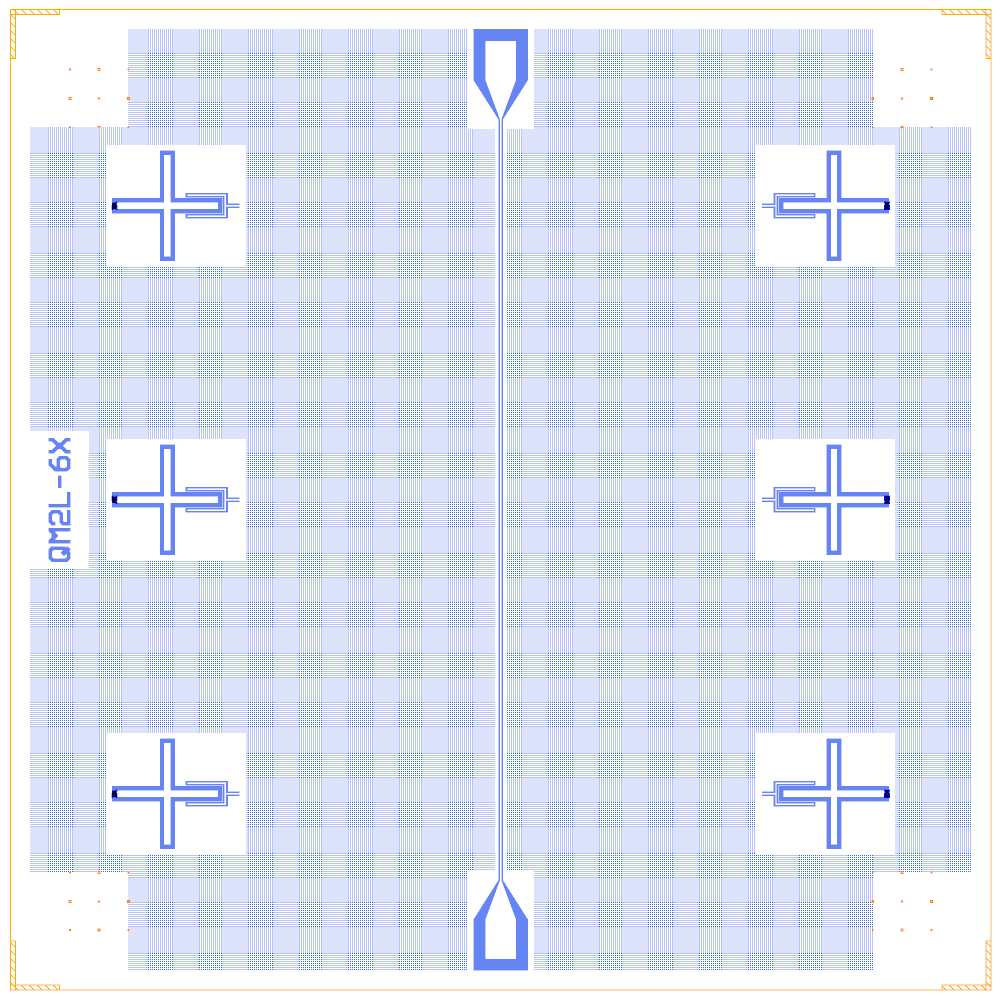

In [7]:
CLAW = dict(connector_location="90", connector_type="0", claw_length=190, claw_gap=6, claw_width=10,
            claw_cpw_length=60, claw_cpw_width=10, ground_spacing=5)
CROSS = dict(cross_length=260, cross_width=35, cross_gap=20, connection_pads={"c": CLAW})
SITES = (("Q1_L", -1700, 1500), ("Q2_L", -1700, 0), ("Q3_L", -1700, -1500),
         ("Q1_R", 1700, 1500), ("Q2_R", 1700, 0), ("Q3_R", 1700, -1500))   # source (x, y), µm
qubits = {}
with d.batch():
    for name, x, y in SITES:
        qubits[name] = d.add(name, "metal:TransmonCross", at=(X0 + x, Y0 + y), rot=-90 if x < 0 else 90,
                             junction=JJ, **CROSS, **JJP)
print(qubits["Q1_L"])
snap(d, OUT / "qm2litho_6xmon_components.png", size=(1000, 1000), width=360);

## 5 · Routes: six λ/4 hanger readouts

Each source readout is a `RouteMeander` from the claw to a `CoupledLineTee` on the feedline. In the rebuild it is one
qcc route: claw → meander → a 200 µm section running along the feedline with a 4 µm ground strip → short to ground.
- `fl.hanger(near=(x, y), length=200, side=..., ground_gap=4, end="short")` centres the coupled section at the
  feedline point nearest (x, y); here 100 µm below each qubit's centre, as in the source. Placing it by position
  (`near=`) and not by arclength along the feedline keeps it in place when the pads move.
- `meander=L` fixes the total length: the source's meander L = v / (4 f) **plus the tee's own 200 µm coupled section and
  110 µm down leg** (310 µm), which are part of the physical λ/4. The resonators therefore come out below the source's
  targets, which ignore the tee.
- 5 meanders, 70 µm bends (the source's fillet).

{'FL': 3834.0, 'R_Q1_L': 5215.2, 'R_Q2_L': 5032.2, 'R_Q3_L': 4945.4, 'R_Q1_R': 4877.6, 'R_Q2_R': 4817.9, 'R_Q3_R': 4784.9}


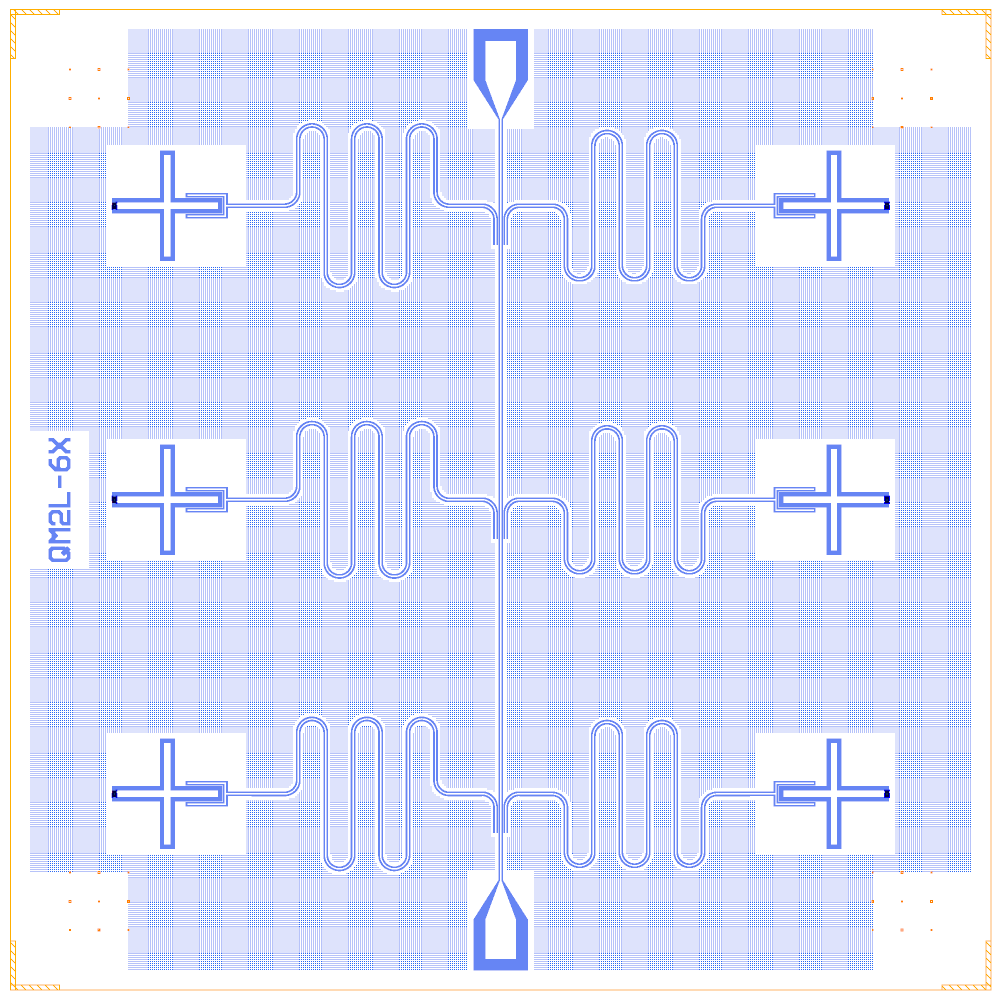

In [8]:
F_GHZ = (6.116, 6.353, 6.472, 6.568, 6.655, 6.704)  # source targets, in site order
CLT_LINE = 200 + 110                             # the tee's coupled section + down leg (part of the λ/4)
with d.batch():
    for (name, x, y), f in zip(SITES, F_GHZ):
        L_src = 1.20e8 / (4 * f * 1e9) * 1e6     # source meander length (µm)
        hg = fl.hanger(near=(X0, Y0 + y - 100), length=200, side="right" if x < 0 else "left", ground_gap=4,
                       direction="forward", end="short")
        d.route(f"R_{name}", qubits[name].c, hg, meander=round(L_src + CLT_LINE, 1), r=70).set(meanders=5)
        d.sim_group(name, [name, f"R_{name}", "FL"])
        d.targets(**{f"R_{name}": {"f_GHz": f}})
rebuild(d)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})
snap(d, OUT / "qm2litho_6xmon_routes.png", size=(1000, 1000), width=360);

## 6 · PDK placement: centring

The source chip is symmetric about its centre and the rebuild keeps the source coordinates, so the content is already
centred: `center_in_die(d)` measures the bounding box of every instance and route and returns (0, 0) when it is
within 50 µm of the die centre (it would shift everything otherwise).

In [9]:
print("shift applied (µm):", center_in_die(d))

shift applied (µm): (0.0, 0.0)


## 7 · DRC

`d.drc()` checks connectivity (dangling ports, overlaps, route crossings, netlist opens and shorts) and the PDK margins:
- **errors** would make the chip wrong; there must be none;
- **warnings** are worth a look but can be intended: here the `TransmonCross` junction attachment points
  (`squid_a` / `squid_b`; the cell draws its own junction), not route ends;
- **PDK design warnings** flag values outside the PDK margins (`pdk_rn`, `pdk_fq`, `pad_edge`, `pdk_claw`); they are
  reported, never enforced. Here: `pdk_rn` on all six qubits (the source's 15.9 nH).

Expected (this run): **no errors**; 12 `dangling_port` warnings, the six crosses' `squid_a` / `squid_b`; 6 `pdk_rn`
(R_n 107.1 kΩ). No `pad_edge`: both launchpads sit at 100 µm.

`pdk_report(d)` sums up the PDK checks.

In [10]:
rebuild(d)
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

**0 errors · 12 warnings · 6 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 12 | Q1_L.squid_a is not connected (no route or snap) |
| PDK design warning | `pdk_rn` | 6 | Q1_L: junction R_n 107.1 kΩ is outside the PDK window 40–50 kΩ (L_J 16.0343 nH) |

| check | value |
|---|---|
| cheese | the original design's rule (drawn in the build): size 2, gap 8, rows 1000, clearance 5 |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Junction × 6 |
| PDK design warnings | 6 (pdk_rn × 6) |
| pdk_rn | Q1_L: junction R_n 107.1 kΩ is outside the PDK window 40–50 kΩ (L_J 16.0343 nH) |
| pdk_rn | Q2_L: junction R_n 107.1 kΩ is outside the PDK window 40–50 kΩ (L_J 16.0343 nH) |
| pdk_rn | Q3_L: junction R_n 107.1 kΩ is outside the PDK window 40–50 kΩ (L_J 16.0343 nH) |
| pdk_rn | Q1_R: junction R_n 107.1 kΩ is outside the PDK window 40–50 kΩ (L_J 16.0343 nH) |
| pdk_rn | Q2_R: junction R_n 107.1 kΩ is outside the PDK window 40–50 kΩ (L_J 16.0343 nH) |
| pdk_rn | Q3_R: junction R_n 107.1 kΩ is outside the PDK window 40–50 kΩ (L_J 16.0343 nH) |

## 8 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit. Each grounded `TransmonCross` is an island node with its junction to
ground and a claw node coupled to it; each readout is a λ/4 `TLres` from the claw node, with a `HANGER` (κ) to the
feedline node `FL`, which carries the two 50 Ω launchpad ports.

In [11]:
lb = d.lom()
show_netlist(lb)
print(lom_summary(lb))

**14 nodes · 38 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `FL` | `FL`, `WB_TOP.pad`, `WB_BOT.pad` |
| `Q1_L` | `Q1_L.island` |
| `Q1_L.c` | `Q1_L.c` |
| `Q2_L` | `Q2_L.island` |
| `Q2_L.c` | `Q2_L.c` |
| `Q3_L` | `Q3_L.island` |
| `Q3_L.c` | `Q3_L.c` |
| `Q1_R` | `Q1_R.island` |
| `Q1_R.c` | `Q1_R.c` |
| `Q2_R` | `Q2_R.island` |
| `Q2_R.c` | `Q2_R.c` |
| `Q3_R` | `Q3_R.island` |
| `Q3_R.c` | `Q3_R.c` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_WB_TOP` | R | `FL` – `gnd` | 50 Ω |
| `Port_WB_BOT` | R | `FL` – `gnd` | 50 Ω |
| `C_Q1_L` | C | `Q1_L` – `gnd` | 132 fF |
| `J_Q1_L` | JJ | `Q1_L` – `gnd` | Lj 16 nH, Cj 6.3 fF |
| `Cg_Q1_L_c` | C | `Q1_L` – `Q1_L.c` | 4.6 fF |
| `Cc_Q1_L_c` | C | `Q1_L.c` – `gnd` | 82.3 fF |
| `C_Q2_L` | C | `Q2_L` – `gnd` | 132 fF |
| `J_Q2_L` | JJ | `Q2_L` – `gnd` | Lj 16 nH, Cj 6.3 fF |
| `Cg_Q2_L_c` | C | `Q2_L` – `Q2_L.c` | 4.6 fF |
| `Cc_Q2_L_c` | C | `Q2_L.c` – `gnd` | 82.3 fF |
| `C_Q3_L` | C | `Q3_L` – `gnd` | 132 fF |
| `J_Q3_L` | JJ | `Q3_L` – `gnd` | Lj 16 nH, Cj 6.3 fF |
| `Cg_Q3_L_c` | C | `Q3_L` – `Q3_L.c` | 4.6 fF |
| `Cc_Q3_L_c` | C | `Q3_L.c` – `gnd` | 82.3 fF |
| `C_Q1_R` | C | `Q1_R` – `gnd` | 132 fF |
| `J_Q1_R` | JJ | `Q1_R` – `gnd` | Lj 16 nH, Cj 6.3 fF |
| `Cg_Q1_R_c` | C | `Q1_R` – `Q1_R.c` | 4.6 fF |
| `Cc_Q1_R_c` | C | `Q1_R.c` – `gnd` | 82.3 fF |
| `C_Q2_R` | C | `Q2_R` – `gnd` | 132 fF |
| `J_Q2_R` | JJ | `Q2_R` – `gnd` | Lj 16 nH, Cj 6.3 fF |
| `Cg_Q2_R_c` | C | `Q2_R` – `Q2_R.c` | 4.6 fF |
| `Cc_Q2_R_c` | C | `Q2_R.c` – `gnd` | 82.3 fF |
| `C_Q3_R` | C | `Q3_R` – `gnd` | 132 fF |
| `J_Q3_R` | JJ | `Q3_R` – `gnd` | Lj 16 nH, Cj 6.3 fF |
| `Cg_Q3_R_c` | C | `Q3_R` – `Q3_R.c` | 4.6 fF |
| `Cc_Q3_R_c` | C | `Q3_R.c` – `gnd` | 82.3 fF |
| `R_Q1_L` | TLres | `Q1_L.c` – `gnd` | lambda/4, 5215 µm, 6.042 GHz |
| `K_R_Q1_L` | HANGER | `Q1_L.c` – `FL` | κ 0.0914 MHz (L 200 µm) |
| `R_Q2_L` | TLres | `Q2_L.c` – `gnd` | lambda/4, 5032 µm, 6.261 GHz |
| `K_R_Q2_L` | HANGER | `Q2_L.c` – `FL` | κ 0.102 MHz (L 200 µm) |
| `R_Q3_L` | TLres | `Q3_L.c` – `gnd` | lambda/4, 4945 µm, 6.371 GHz |
| `K_R_Q3_L` | HANGER | `Q3_L.c` – `FL` | κ 0.107 MHz (L 200 µm) |
| `R_Q1_R` | TLres | `Q1_R.c` – `gnd` | lambda/4, 4878 µm, 6.460 GHz |
| `K_R_Q1_R` | HANGER | `Q1_R.c` – `FL` | κ 0.112 MHz (L 200 µm) |
| `R_Q2_R` | TLres | `Q2_R.c` – `gnd` | lambda/4, 4818 µm, 6.540 GHz |
| `K_R_Q2_R` | HANGER | `Q2_R.c` – `FL` | κ 0.116 MHz (L 200 µm) |
| `R_Q3_R` | TLres | `Q3_R.c` – `gnd` | lambda/4, 4785 µm, 6.585 GHz |
| `K_R_Q3_R` | HANGER | `Q3_R.c` – `FL` | κ 0.118 MHz (L 200 µm) |

**Unconnected ports:** none

{'nodes': 13, 'branches': 38, 'controls': 0, 'unconnected': 0}


## 9 · LOM simulation (per qubit / readout pair, with the feedline)

Each qubit is simulated with its readout and the feedline (QuCat normal modes, then the QuTiP dressed values). Targets
in brackets are the source's L = v/(4f) values for the meander alone; the rebuild's λ/4 also includes the tee's 310 µm,
so f_r sits lower. The source states no qubit frequency (≈ 3.7 GHz if it matches the SQuADDS entry); the design sets no qubit
target, so the DRC has no `pdk_fq` warning to give.

What the table shows (this run):
- every qubit at **3.183 GHz** (α −151 MHz) with the drawn trilayer junction (L_J 16.03 nH, C_J 6.3 fF instead of the
  source's assumed 2 fF): below the PDK band of 4–8 GHz; step 12 shows what the PDK nominal junction would do;
- the readouts at **5.431 … 5.869 GHz**, 0.69–0.84 GHz (11–12 %) below the source's 6.116 … 6.704 GHz: the tee's
  310 µm (≈ 6 % of each λ/4) is in our length, the claw loads the open end and the PDK CPW on sapphire is slower than
  the source's v = 1.2 × 10⁸ m/s. Flagged, not retuned;
- κ 0.060–0.075 MHz through the 200 µm hangers; χ −0.11 … −0.12 MHz (the qubits sit 2.2–2.7 GHz below their
  readouts).

In [12]:
groups = {name: [name, f"R_{name}", "FL"] for name, _, _ in SITES}
res = simulate_groups(d, groups)
display(Markdown(groups_md(res, d.data["targets"])))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q1_L | Q1_L | 3.1828 | -150.9 | R_Q1_L | 5.4312 (6.116) | 0.0597 | -0.124 |
| Q2_L | Q2_L | 3.1829 | -150.9 | R_Q2_L | 5.6091 (6.353) | 0.0655 | -0.117 |
| Q3_L | Q3_L | 3.1829 | -150.9 | R_Q3_L | 5.6977 (6.472) | 0.0685 | -0.113 |
| Q1_R | Q1_R | 3.1829 | -150.9 | R_Q1_R | 5.7688 (6.568) | 0.071 | -0.111 |
| Q2_R | Q2_R | 3.1829 | -150.9 | R_Q2_R | 5.833 (6.655) | 0.0733 | -0.109 |
| Q3_R | Q3_R | 3.1829 | -150.9 | R_Q3_R | 5.8691 (6.704) | 0.0747 | -0.108 |

## 10 · FEM: send the job

Every qubit's sim group (qubit, readout, feedline) is exported as a Q3D C-matrix job (capacitances by net name) and an
eigenmode/EPR job, in self-contained folders `build/jobs/<design>_<group>_<analysis>`. Exporting again replaces a
folder, results included. Simulation exports never carry cheese.

`RUN_FEM = False` only exports. With `RUN_FEM = True` and AEDT 2024 R1 (or newer) on this machine, `send_fem_jobs` solves
each job in a **new batch, non-graphical AEDT** (`solve_job`); an AEDT window you have open is never touched. Elsewhere:
`qcc hfss solve build/jobs/<job>`.

In [13]:
RUN_FEM = False                                  # True: solve the jobs now in a new batch AEDT (2024 R1 or newer)
DESIGN = d.save(OUT / "qm2litho_6xmon.json")
jobs = export_sims(DESIGN, list(groups), analysis="q3d_cmatrix")
jobs_eig = export_sims(DESIGN, list(groups), analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))
if RUN_FEM:
    send_fem_jobs(DESIGN, list(groups), analyses=["q3d_cmatrix", "eigenmode_epr"], run=True)

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q1_L | `build/jobs/qm2litho_6xmon_Q1_L_q3d_cmatrix` | 1 · junction · `Q1_L.junction`<br>2 · waveguide · `Q1_L.c`<br>3 · lumped · `WB_BOT.pad`<br>4 · lumped · `WB_TOP.pad` | `Q1_L.island`, `Q1_L.c`, `WB_BOT.pad` |
| Q2_L | `build/jobs/qm2litho_6xmon_Q2_L_q3d_cmatrix` | 1 · junction · `Q2_L.junction`<br>2 · waveguide · `Q2_L.c`<br>3 · lumped · `WB_BOT.pad`<br>4 · lumped · `WB_TOP.pad` | `Q2_L.island`, `Q2_L.c`, `WB_BOT.pad` |
| Q3_L | `build/jobs/qm2litho_6xmon_Q3_L_q3d_cmatrix` | 1 · junction · `Q3_L.junction`<br>2 · waveguide · `Q3_L.c`<br>3 · lumped · `WB_BOT.pad`<br>4 · lumped · `WB_TOP.pad` | `Q3_L.island`, `Q3_L.c`, `WB_BOT.pad` |
| Q1_R | `build/jobs/qm2litho_6xmon_Q1_R_q3d_cmatrix` | 1 · junction · `Q1_R.junction`<br>2 · waveguide · `Q1_R.c`<br>3 · lumped · `WB_BOT.pad`<br>4 · lumped · `WB_TOP.pad` | `Q1_R.island`, `Q1_R.c`, `WB_BOT.pad` |
| Q2_R | `build/jobs/qm2litho_6xmon_Q2_R_q3d_cmatrix` | 1 · junction · `Q2_R.junction`<br>2 · waveguide · `Q2_R.c`<br>3 · lumped · `WB_BOT.pad`<br>4 · lumped · `WB_TOP.pad` | `Q2_R.island`, `Q2_R.c`, `WB_BOT.pad` |
| Q3_R | `build/jobs/qm2litho_6xmon_Q3_R_q3d_cmatrix` | 1 · junction · `Q3_R.junction`<br>2 · waveguide · `Q3_R.c`<br>3 · lumped · `WB_BOT.pad`<br>4 · lumped · `WB_TOP.pad` | `Q3_R.island`, `Q3_R.c`, `WB_BOT.pad` |
| Q1_L | `build/jobs/qm2litho_6xmon_Q1_L_eigenmode_epr` | 1 · junction · `Q1_L.junction`<br>2 · lumped · `WB_BOT.pad`<br>3 · lumped · `WB_TOP.pad` | `Q1_L.island`, `WB_BOT.pad` |
| Q2_L | `build/jobs/qm2litho_6xmon_Q2_L_eigenmode_epr` | 1 · junction · `Q2_L.junction`<br>2 · lumped · `WB_BOT.pad`<br>3 · lumped · `WB_TOP.pad` | `Q2_L.island`, `WB_BOT.pad` |
| Q3_L | `build/jobs/qm2litho_6xmon_Q3_L_eigenmode_epr` | 1 · junction · `Q3_L.junction`<br>2 · lumped · `WB_BOT.pad`<br>3 · lumped · `WB_TOP.pad` | `Q3_L.island`, `WB_BOT.pad` |
| Q1_R | `build/jobs/qm2litho_6xmon_Q1_R_eigenmode_epr` | 1 · junction · `Q1_R.junction`<br>2 · lumped · `WB_BOT.pad`<br>3 · lumped · `WB_TOP.pad` | `Q1_R.island`, `WB_BOT.pad` |
| Q2_R | `build/jobs/qm2litho_6xmon_Q2_R_eigenmode_epr` | 1 · junction · `Q2_R.junction`<br>2 · lumped · `WB_BOT.pad`<br>3 · lumped · `WB_TOP.pad` | `Q2_R.island`, `WB_BOT.pad` |
| Q3_R | `build/jobs/qm2litho_6xmon_Q3_R_eigenmode_epr` | 1 · junction · `Q3_R.junction`<br>2 · lumped · `WB_BOT.pad`<br>3 · lumped · `WB_TOP.pad` | `Q3_R.island`, `WB_BOT.pad` |

## 11 · Bring the results back

When a job has results (`build/jobs/<job>/results/results.json`), `fill(model, design, job)` puts the extracted
capacitances into the LOM by net name (`Q1_L.island`, `Q1_L.c`, …), next to the estimates, and the LOM can be simulated
again on them. Until a solve has run, the cell says what would appear.

In [14]:
filled, md = fem_back(lb.model, DESIGN, {**{f"{g} · q3d": v for g, v in jobs.items()},
                                         **{f"{g} · eigenmode": v for g, v in jobs_eig.items()}})
display(Markdown(md))

No FEM results yet for Q1_L · q3d, Q2_L · q3d, Q3_L · q3d, Q1_R · q3d, Q2_R · q3d, Q3_R · q3d, Q1_L · eigenmode, Q2_L · eigenmode, Q3_L · eigenmode, Q1_R · eigenmode, Q2_R · eigenmode, Q3_R · eigenmode: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 12 · Iterate: change one property and re-simulate

The LOM is cheap, so a design change can be checked in seconds. The source's 15.9 nH junction puts the qubits at
3.18 GHz, below the PDK's 4–8 GHz band, with R_n outside the window. The rule is to flag it, not to retune; but what
would the PDK nominal junction (R_n 45 kΩ, L_J ≈ 6.7 nH) do? Q1_L gets that junction in a copy. This run: f_q rises from
3.183 to 4.847 GHz, closer to its readout (5.43 GHz), so |χ| grows from 0.12 to 1.42 MHz; α goes from −151 to −135 MHz
(the larger C_J) and the readout does not move. `design_copy` opens a second, non-live Designer on the saved design, so the design
file stays as it is.

In [15]:
d2 = design_copy(DESIGN)
JJP45, JJ45 = trilayer_junction("metal:TransmonCross", lj_nH=6.7344)   # the PDK nominal junction, R_n ≈ 45 kΩ
d2["Q1_L"].set(junction=JJ45, **JJP45)
print("Q1_L junction in the copy:", JJ45, f"→ R_n {rn_from_lj(JJ45['Lj_nH']) / 1e3:.1f} kΩ")
res2 = simulate_groups(d2, {"Q1_L": groups["Q1_L"]})
display(Markdown(params_delta_md({"Q1_L": res["Q1_L"]}, res2)))

Q1_L junction in the copy: {'Lj_nH': 6.7344, 'Cj_fF': 15.0} → R_n 45.0 kΩ


| parameter | before | after | Δ |
|---|---|---|---|
| `Q1_L: Q1_L.f_q_GHz` | 3.1828 | 4.8469 | +1.664 |
| `Q1_L: Q1_L.alpha_MHz` | -150.85 | -134.75 | +16.1 |
| `Q1_L: R_Q1_L.chi_MHz` | -0.12387 | -1.4193 | -1.295 |
| `Q1_L: R_Q1_L.f_GHz` | 5.4312 | 5.4339 | +0.002695 |
| `Q1_L: R_Q1_L.kappa_MHz` | 0.059682 | 0.059278 | -0.0004031 |

## 13 · Build and export

- **Design file:** `d.save(...)` wrote `examples/designs/community/qm2litho_6xmon.json` (step 10); `Designer.load`
  reopens it.
- **Fab mask with the original's cheese.** The build drew the source's antidot field (the chip's `cheese` rule,
  step 2) into KQC's `ground_grid` layer, so `export_fab` keeps it (`cheese source: build`, no PDK band added) and
  writes only the PDK fab layers, with corner rounding; every hole is on 3/0 as well as on 1/0. `qcc mask` keeps it
  too.
- **Simulation export options:** `build_simulation(design, group, analysis, airbridges=True)` keeps airbridges in a FEM
  export (this chip has none); cheese is never exported.
- **The same from the command line:** `qcc build examples/designs/community/qm2litho_6xmon.json`, `qcc design drc …`,
  `qcc mask …` (the fab
  file, with the build's antidots), `qcc sim build … -g Q1_L -a q3d_cmatrix`, `qcc hfss solve build/jobs/<job>`.

In [16]:
rebuild(d)
FAB = Path("build") / "qm2litho_6xmon_fab.oas"
display(Markdown(fab_layers_md(d, path=FAB, cheese=True, rounding=True)))   # keeps the build's antidots

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 170919 |
| 2/0 | JJ_STRAIGHT | 6 |
| 3/0 | M3 | 170903 |
| 4/0 | JJ_BENT | 6 |
| 50/0 | HSQ | 12 |
| 51/0 | SPACER_1 | 12 |
| 52/0 | SPACER_2 | 12 |
| 53/0 | SPACER_3 | 12 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 170899 holes on the mask.

→ `build/qm2litho_6xmon_fab.oas`

## 14 · Snapshots

The full chip; qubit Q1_L with its claw; its trilayer junction; the two facing couplers of row 1 on the feedline; and
the fab mask round Q1_L's coupler, where the antidot field (holes on 1/0 and 3/0) stops 5 µm from the 3/0 keep-outs (15 µm from the line
etch).

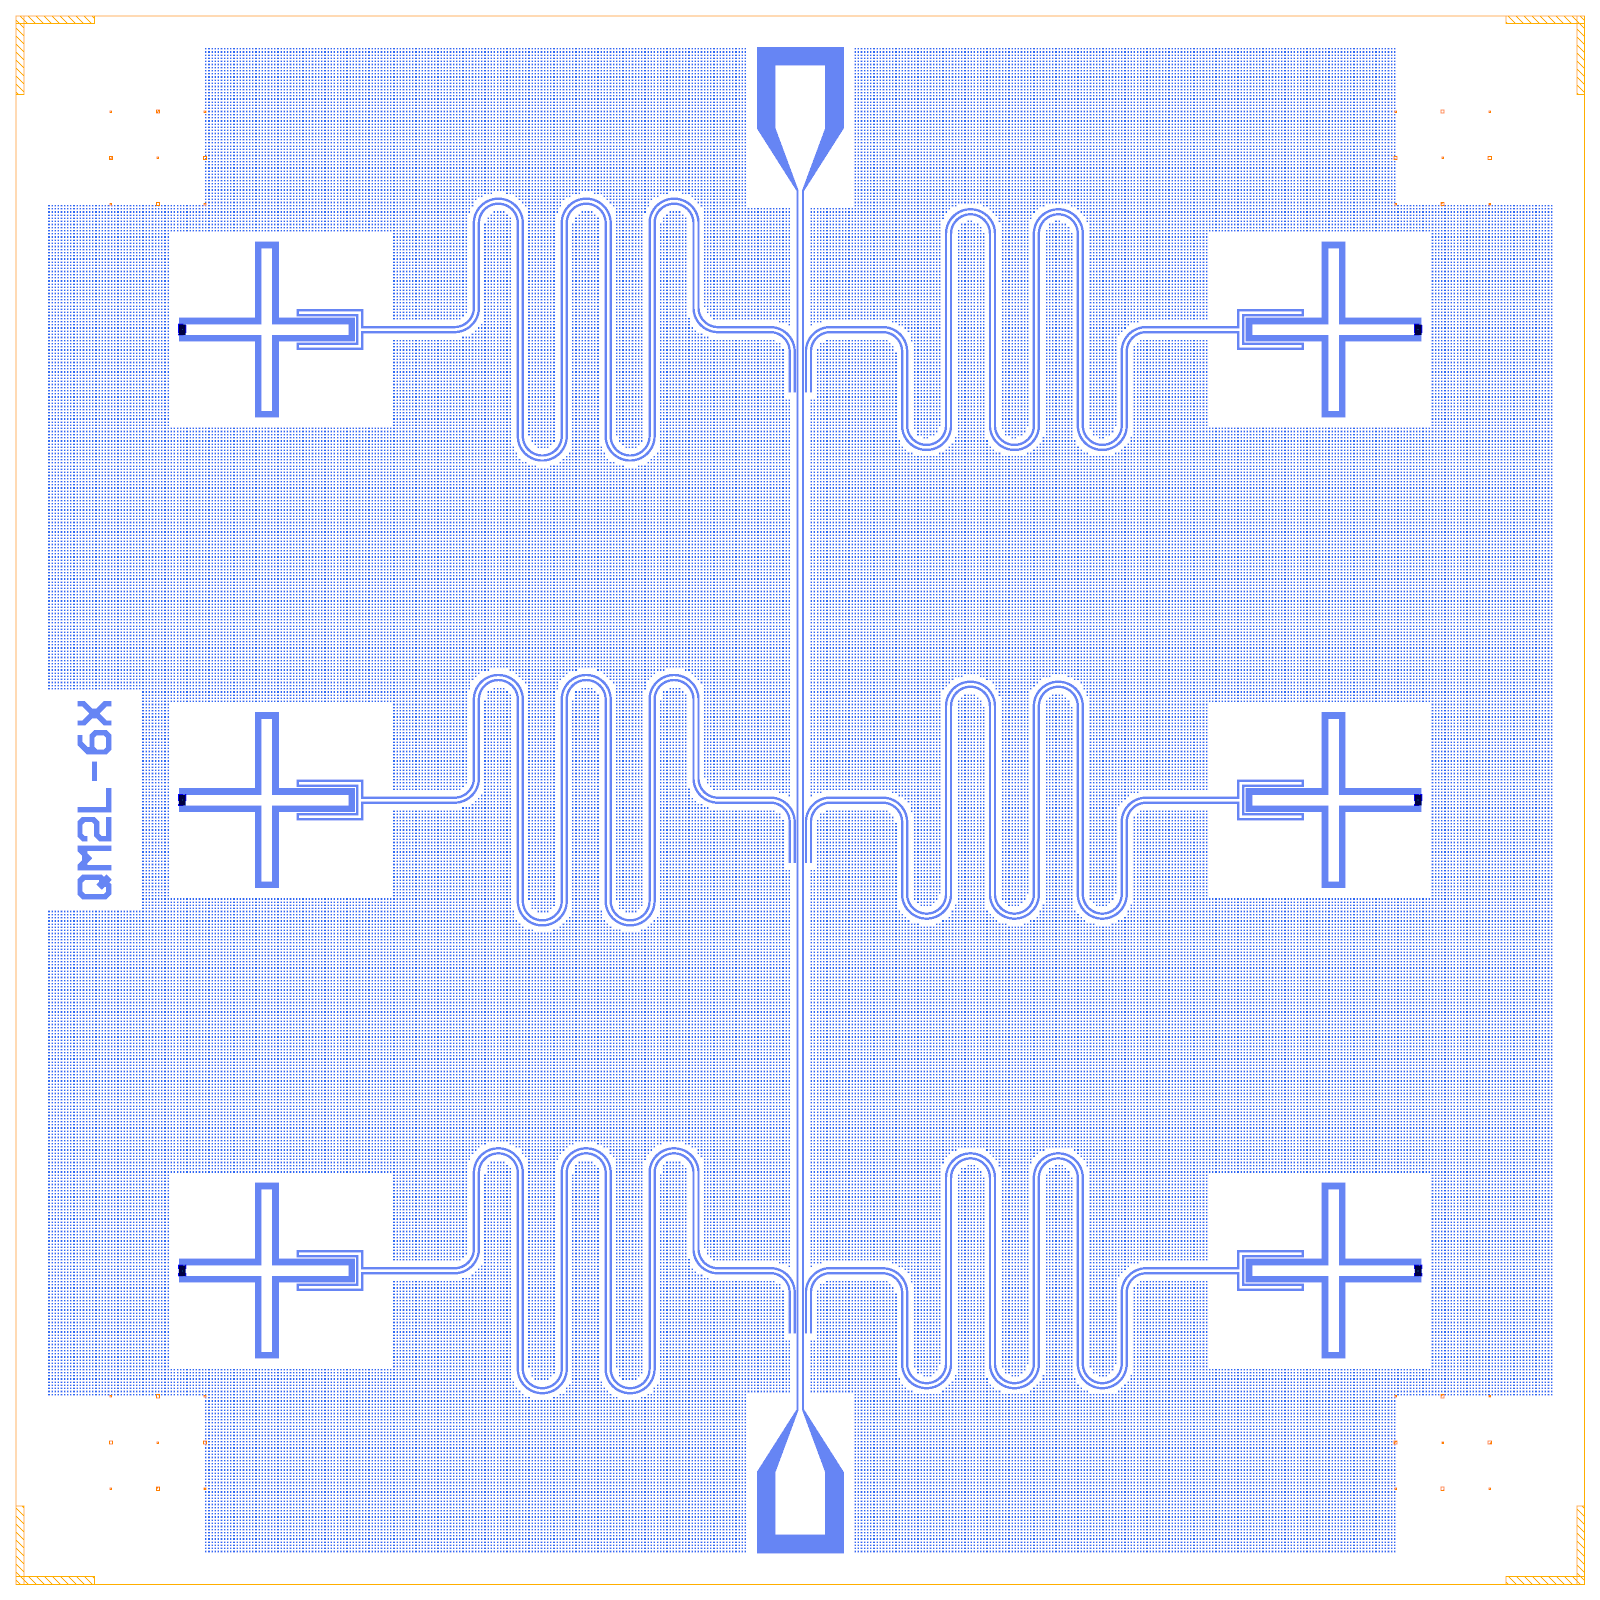

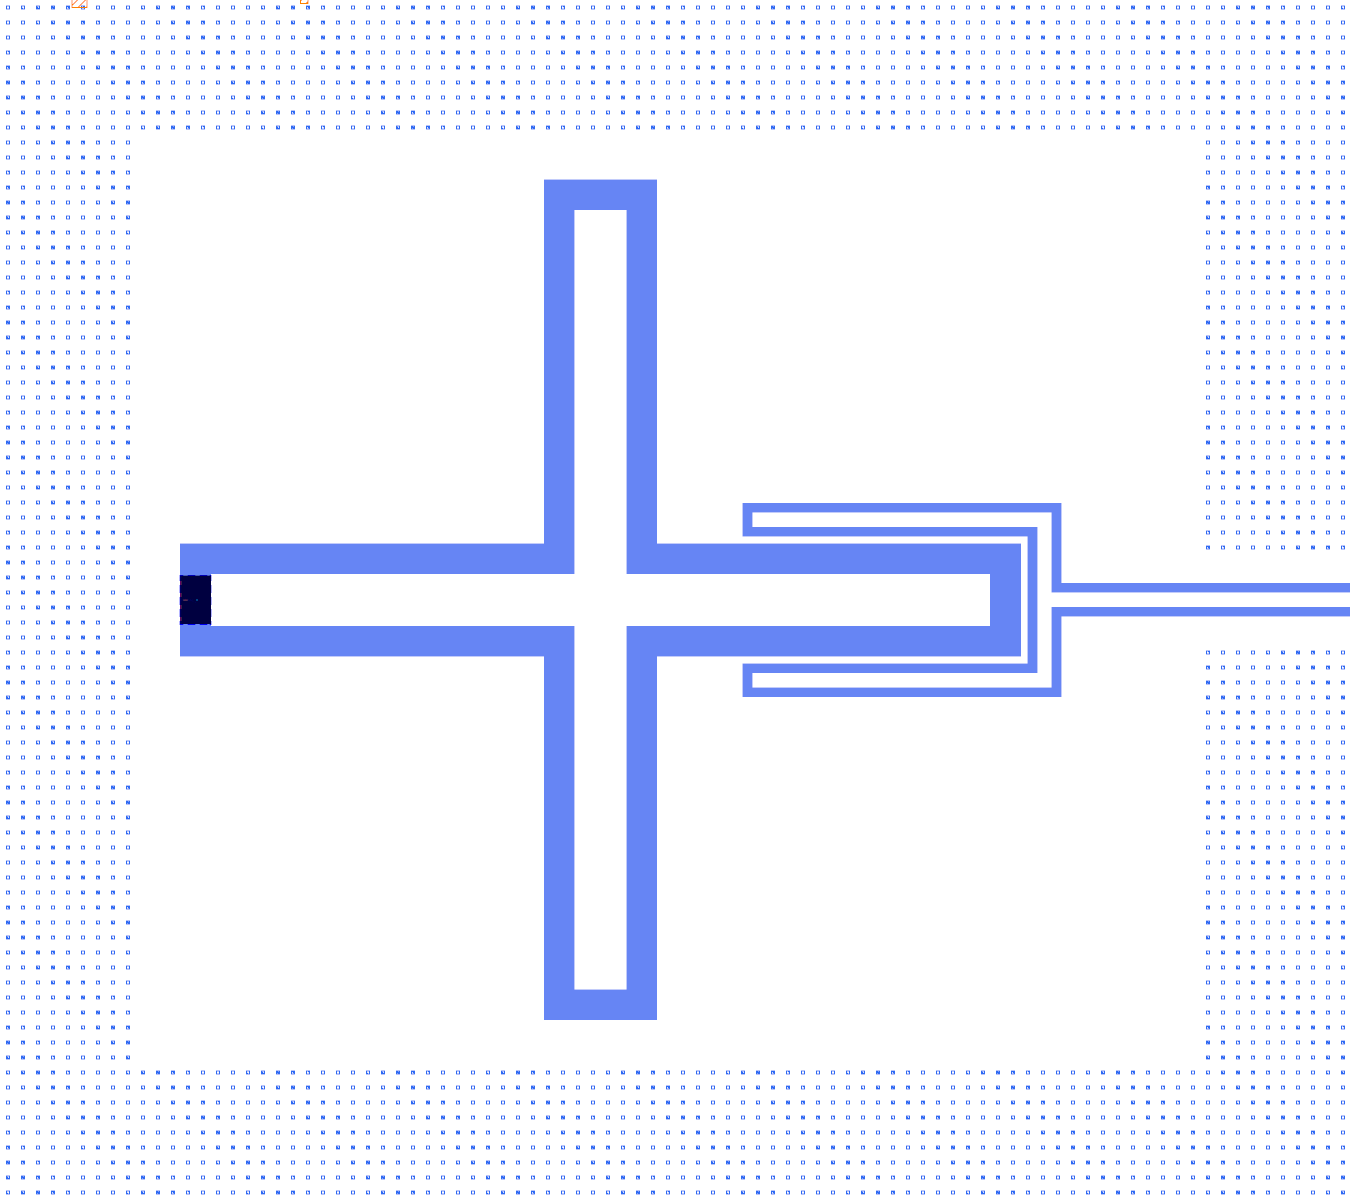

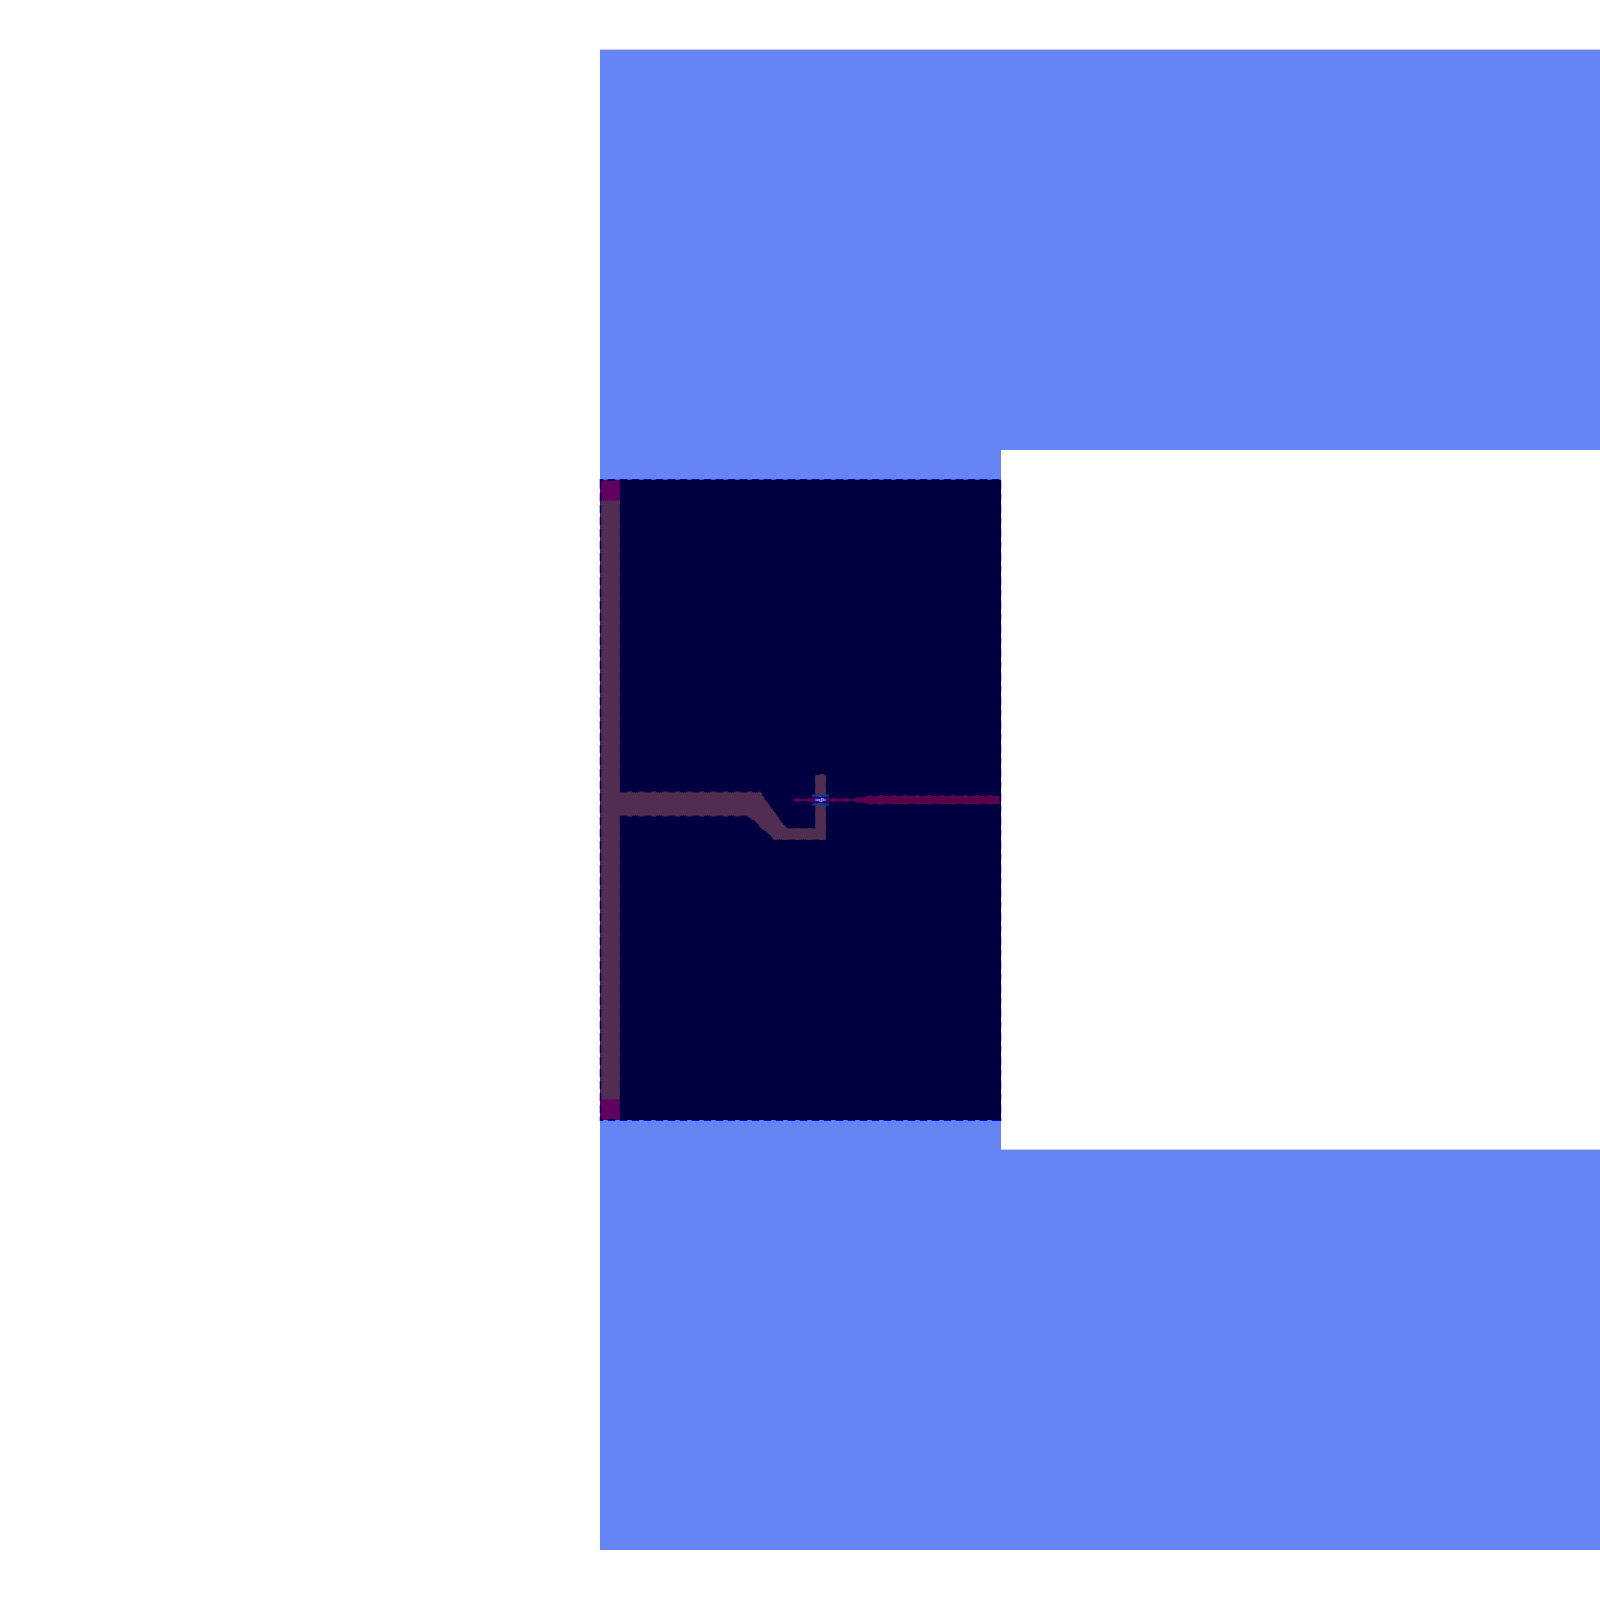

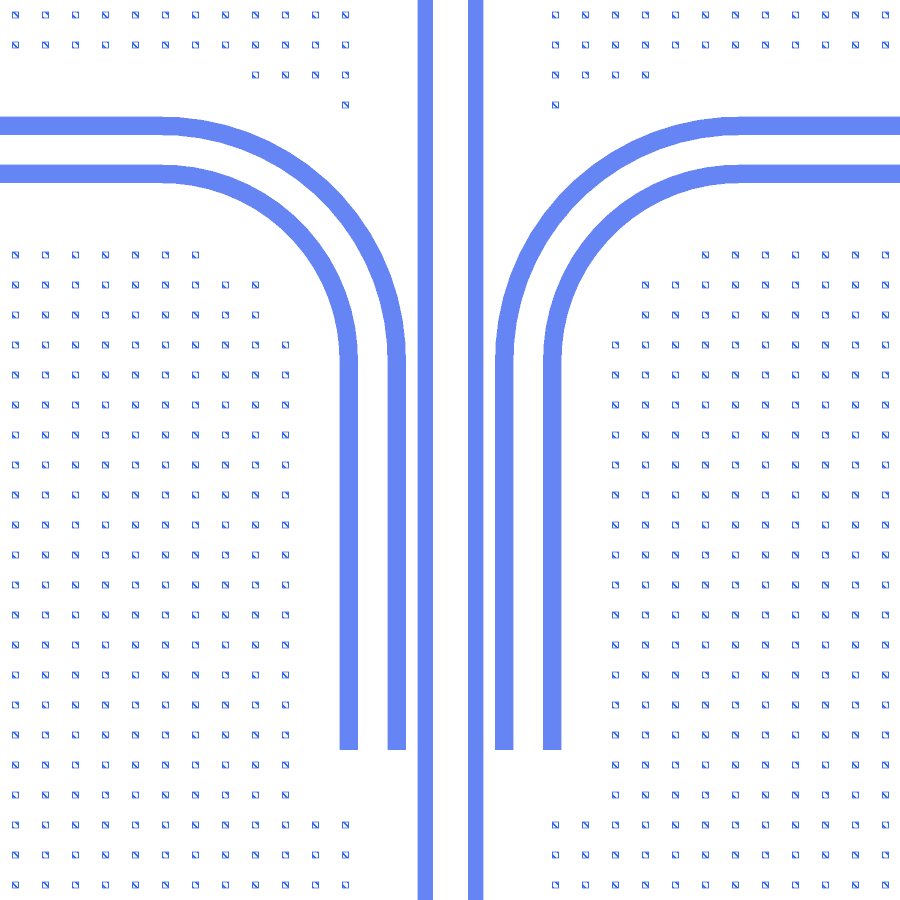

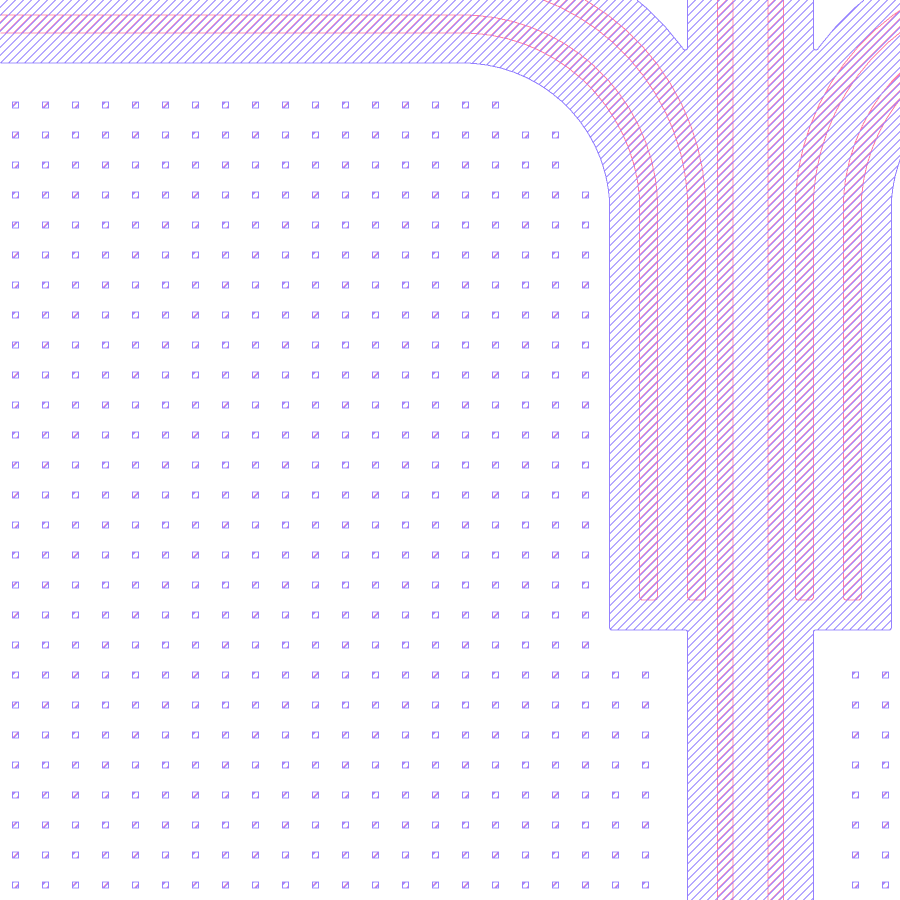

In [17]:
snap(d, OUT / "qm2litho_6xmon.png", size=(1600, 1600))
qx, qy = X0 - 1700, Y0 + 1500
snap(d, OUT / "qm2litho_6xmon_q1l.png", box=(qx - 400, qy - 400, qx + 500, qy + 400), size=(1350, 1200), width=450)
snap(d, OUT / "qm2litho_6xmon_jj.png", box=(qx - 310, qy - 40, qx - 230, qy + 40), width=300)
snap(d, OUT / "qm2litho_6xmon_couplers.png", box=(X0 - 150, qy - 250, X0 + 150, qy + 50), size=(900, 900), width=360)
snap_file(FAB, OUT / "qm2litho_6xmon_cheese.png", box=(X0 - 250, qy - 300, X0 + 50, qy), size=(900, 900), width=360);

## 15 · Summary

- **Matches the source:** the qubit and launchpad cells with their options and positions, the feedline CPW, the six
  readout lengths (source meander + the tee's 310 µm), the coupled sections, the source's L_J, the antidot field (2 µm / 10 µm,
  15 µm from the line etch), drawn by the build and kept in the mask (170 899 holes).
- **Changed by the PDK:** the PDK frame on the 5 × 5 mm die, sapphire, drawn trilayer junctions, the launchpads 100 µm
  inside the die edge (the source's overhang removed; the feedline is shorter), content centred (no shift needed).
- **Open PDK design warnings:** `pdk_rn` on all six qubits (R_n 107 kΩ at the source's 15.9 nH; flagged, not
  retuned). The qubits sit at 3.18 GHz, below the PDK band (no target, so no `pdk_fq`).
- **Differs:** the readouts land 11–12 % below the source's targets (the tee's 310 µm in the λ/4, the claw, the slower
  CPW); the source's 45 µm antidot clearance round the pads is one 15 µm clearance here.
- **Open:** the FEM jobs are exported, not solved (`RUN_FEM = False`).